<a href="https://colab.research.google.com/github/tiramisuuuuuuu/CMPE-252-Final-Project/blob/main/Emotion_Classification_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from google.colab import files
files.upload()

Saving ground-truth.xlsx to ground-truth.xlsx


{'ground-truth.xlsx': b'PK\x03\x04\x14\x00\x06\x00\x08\x00\x00\x00!\x00A7\x82\xcfn\x01\x00\x00\x04\x05\x00\x00\x13\x00\x08\x02[Content_Types].xml \xa2\x04\x02(\xa0\x00\x02\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\

In [3]:
import pandas as pd
df = pd.read_excel("ground-truth.xlsx")
print("Number of rows and columns:", df.shape)
display(df.head())

Number of rows and columns: (1112, 20)


,iteration,app_name,categoryId,reviewId,sentenceId,at,score,feature,review,sentence,Joy,Trust,Fear,Surprise,Sadness,Disgust,Anger,Anticipation,Neutral,Reject
0,iteration_10,Telegram,COMMUNICATION,e19eb64e-fea0-4f11-a113-2d22cb7c4ddd,0,"Aug 30, 2022",5,f_339,"Telegram is not only the best messanger, but t...","Telegram is not only the best messanger, but t...",0,1,0,0,0,0,0,0,0,0
1,iteration_10,MixNote NotePad Notes,PRODUCTIVITY,51624ee8-b51e-456e-9d49-b0805fa7e60d,2,"Nov 12, 2017",5,f_30,Simple yet stylish and fast. I really love h...,"From Hiding private notes, cloud sync, and mak...",0,0,0,0,0,0,0,0,1,0
2,iteration_10,Productive - Habit tracker,PRODUCTIVITY,ce62d468-580a-48fe-97fc-08fd5e2bfc1a,2,"Aug 08, 2021",2,f_209,I m not satisfied at all. I got the one year p...,How can you charge so much without the ability...,0,0,0,1,1,0,0,0,0,0
3,iteration_10,Sygic GPS Navigation & Maps,MAPS_AND_NAVIGATION,c06118be-c6c0-42e9-9794-d3892b1b9f68,0,"Aug 31, 2022",5,f_26,Excel GPS navigation. Happy with it 😊,Excel GPS navigation.,1,0,0,0,0,0,0,0,0,0
4,iteration_10,TomTom Sports,HEALTH_AND_FITNESS,31430c83-3698-4aee-b7c4-fb0d57b9f90b,0,"Apr 14, 2020",3,f_278,Good app but I find some problem in synchroniz...,Good app but I find some problem in synchroniz...,1,0,0,0,1,0,0,0,0,0


A 1 means that emotion was assigned to the sentence.
A 0 means it was not assigned.

Notice that a sentence can have more than one 1. This is why our project is called multi-label emotion classification.

We'll use:
- Input (X): The sentence column — the words our model reads.
- Output (y): The emotion columns — the answers we want the model to learn.
We won't use the existing emotion labels as input features, because that would give the model the answers during training.

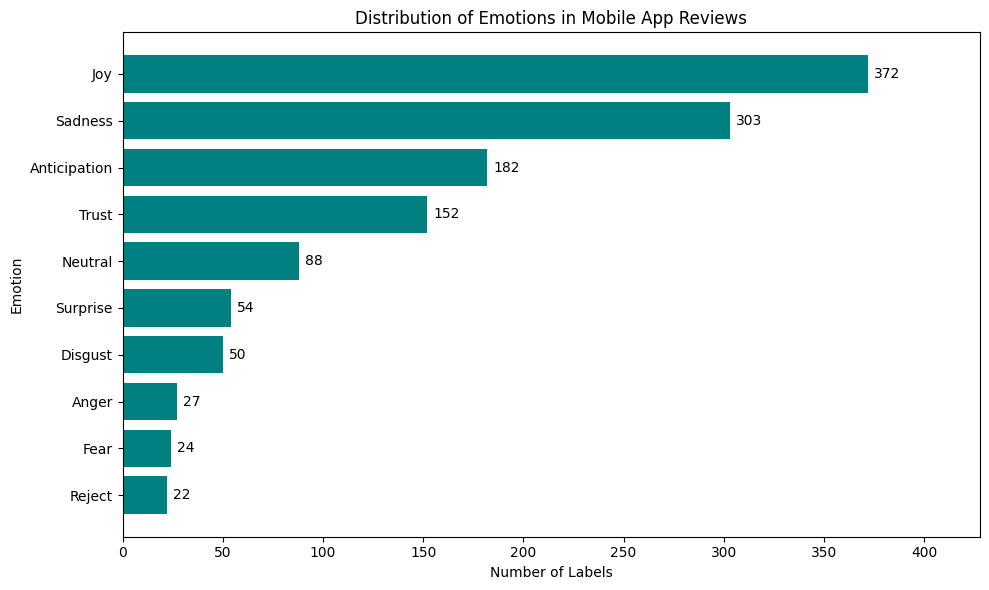

In [4]:

import matplotlib.pyplot as plt

# The emotion columns in our dataset
emotions = [
    "Joy", "Trust", "Fear", "Surprise",
    "Sadness", "Disgust", "Anger",
    "Anticipation", "Neutral", "Reject"
]

# Count how many times each emotion appears
emotion_counts = df[emotions].sum()

# Sort from highest to lowest
emotion_counts = emotion_counts.sort_values(ascending=False)

# Create the chart
plt.figure(figsize=(10, 6))

bars = plt.barh(
    emotion_counts.index,
    emotion_counts.values,
    color="teal"
)

# Show the biggest bar at the top
plt.gca().invert_yaxis()

# Write the count at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 3,
        bar.get_y() + bar.get_height() / 2,
        str(int(width)),
        va="center"
    )

# Add chart titles
plt.title("Distribution of Emotions in Mobile App Reviews")
plt.xlabel("Number of Labels")
plt.ylabel("Emotion")

plt.xlim(0, emotion_counts.max() * 1.15)
plt.tight_layout()
plt.show()


**Check whether our dataset matches the paper**
We're checking three things:
1. Do we have 1,112 sentences?
2. Do the emotion labels total 1,272?
3. Are there any sentences missing?
These are our first data validation checks.

In [5]:
#Check whether our dataset matches the paper
print("Total sentences", len(df))
print("Total emotion labels:", df[emotions].sum().sum())
print("Missing sentences:", df["sentence"].isna().sum())

Total sentences 1112
Total emotion labels: 1274
Missing sentences: 0


Validation check	  |   Expected	       Actual	Status
------------------------------------------------------------------------------
Total sentences	     |    1,112	      |       1,112	    |     Match
Total emotion labels |    1,272	      |        1,274	  |   Difference of 2
Missing sentences	   |     0	        |         0	      |    Match
The paper reports 1,272 labels, but your Excel file contains 1,274.



In [6]:
#Find where the extra two labels come from
# Published counts from the IEEE paper
paper_counts = {
    "Joy": 372,
    "Sadness": 303,
    "Anticipation": 182,
    "Trust": 151,
    "Neutral": 88,
    "Surprise": 54,
    "Disgust": 49,
    "Anger": 27,
    "Fear": 24,
    "Reject": 22
}

#compare published counts with our dataset
comparison = pd.DataFrame({
    "Paper Count": pd.Series(paper_counts),
    "Our Dataset": df[list(paper_counts.keys())].sum()
})

#Calculate differenes
comparison["Difference"] = (
    comparison["Our Dataset"]-comparison["Paper Count"]
)

display(comparison)
print("Total difference:", comparison["Difference"].sum())

,Paper Count,Our Dataset,Difference
Joy,372,372,0
Sadness,303,303,0
Anticipation,182,182,0
Trust,151,152,1
Neutral,88,88,0
Surprise,54,54,0
Disgust,49,50,1
Anger,27,27,0
Fear,24,24,0
Reject,22,22,0


Total difference: 2


In [7]:
#Check how many emotions each sentence contains
# Count the number of labels assigned to each sentence
df["num_emotions"] = df[emotions].sum(axis=1)

#Print the distribution
print("Number of emotions per sentence")
print(df["num_emotions"].value_counts().sort_index())

#Find sentences with multiple emotions labels
multi_emotion = df[df["num_emotions"]>1]

print("\nSentences with multiple labels:", len(multi_emotion))

#Display the first 5 examples
display(
    multi_emotion[["sentence"] + emotions].head()
)

Number of emotions per sentence
num_emotions
1    955
2    152
3      5
Name: count, dtype: int64

Sentences with multiple labels: 157


,sentence,Joy,Trust,Fear,Surprise,Sadness,Disgust,Anger,Anticipation,Neutral,Reject
2,How can you charge so much without the ability...,0,0,0,1,1,0,0,0,0,0
4,Good app but I find some problem in synchroniz...,1,0,0,0,1,0,0,0,0,0
9,Like the app overall but it will not sync with...,1,0,0,0,1,0,0,0,0,0
20,"Its a nice app, it has been working fine for m...",1,0,0,0,1,0,0,0,0,0
21,The only thing that would make this the perfec...,1,0,0,0,0,0,0,1,0,0


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Step A: Define our input and output
X = df["sentence"].fillna("")

emotions = [
    "Joy", "Trust", "Fear", "Surprise",
    "Sadness", "Disgust", "Anger",
    "Anticipation", "Neutral", "Reject"
]

y = df[emotions]

# Step B: Divide data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Step C: Convert sentences into numbers using TF-IDF
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training data prepared successfully!")
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)


Training data prepared successfully!
Training shape: (889, 2264)
Testing shape: (223, 2264)


Use Logistic Regression for classification. It learns patterns in words to predict whether an emotion is present or absent.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# Create our emotion classification model
model = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed!")


Model training completed!


In [10]:
#Check the model
from sklearn.metrics import classification_report

y_pred = model.predict(X_test_tfidf)

print(classification_report(
    y_test,
    y_pred,
    target_names=emotions,
    zero_division = 0
))

              precision    recall  f1-score   support

         Joy       0.72      0.66      0.69        80
       Trust       0.47      0.65      0.55        26
        Fear       1.00      0.17      0.29         6
    Surprise       0.00      0.00      0.00        16
     Sadness       0.47      0.63      0.54        52
     Disgust       0.25      0.07      0.11        14
       Anger       0.50      0.14      0.22         7
Anticipation       0.51      0.66      0.57        35
     Neutral       0.00      0.00      0.00        13
      Reject       0.00      0.00      0.00         3

   micro avg       0.50      0.51      0.51       252
   macro avg       0.39      0.30      0.30       252
weighted avg       0.50      0.51      0.49       252
 samples avg       0.45      0.51      0.47       252



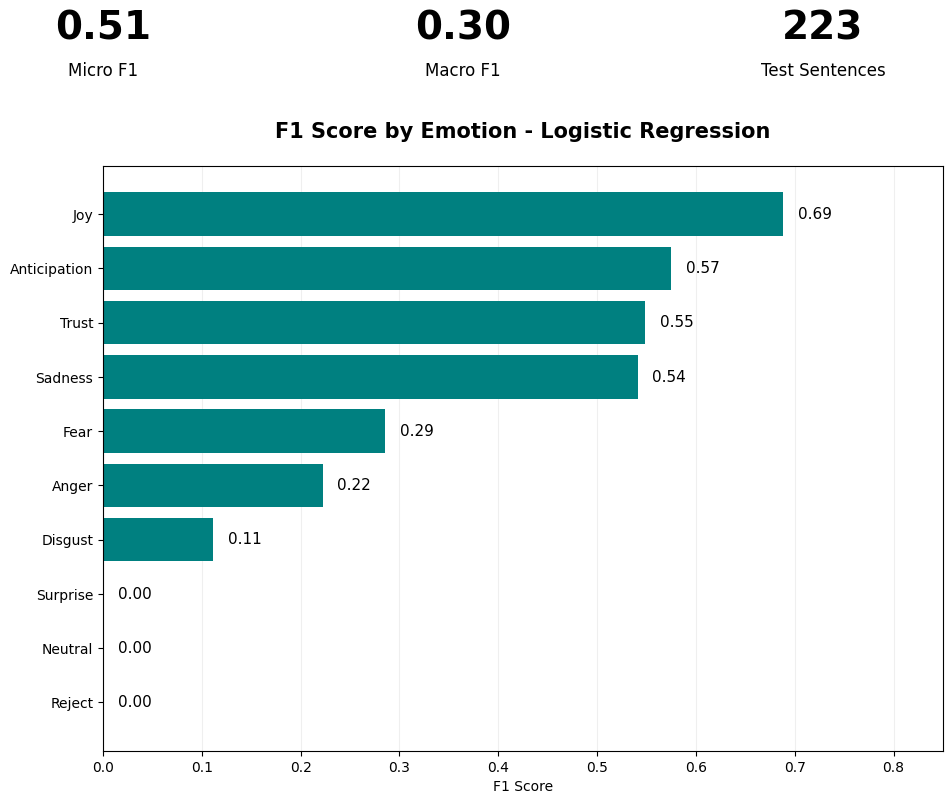

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import f1_score

#1. Calculate model performance
micro_f1 = f1_score(y_test, y_pred, average="micro", zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
test_sentences = len(y_test)

# 2. Calculate F1-score for each emotion
emotion_f1 = f1_score(
    y_test,
    y_pred,
    average=None,
    zero_division=0
)

results = pd.DataFrame({
    "Emotion": emotions,
    "F1 Score": emotion_f1
})

# Sort emotions by F1 score
results = results.sort_values("F1 Score", ascending=False)

# 3. Create the figure
fig = plt.figure(figsize=(12, 9))

# Display summary metrics at the top
fig.text(0.20, 0.91, f"{micro_f1:.2f}",
         fontsize=28, fontweight="bold", ha="center")
fig.text(0.20, 0.87, "Micro F1",
         fontsize=12, ha="center")

fig.text(0.50, 0.91, f"{macro_f1:.2f}",
         fontsize=28, fontweight="bold", ha="center")
fig.text(0.50, 0.87, "Macro F1",
         fontsize=12, ha="center")

fig.text(0.80, 0.91, str(test_sentences),
         fontsize=28, fontweight="bold", ha="center")
fig.text(0.80, 0.87, "Test Sentences",
         fontsize=12, ha="center")

# 4. Create horizontal bar chart
ax = fig.add_axes([0.20, 0.12, 0.70, 0.65])

bars = ax.barh(
    results["Emotion"],
    results["F1 Score"],
    color="teal"
)

ax.invert_yaxis()

# Display numerical F1 values on bars
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=11
    )

ax.set_xlim(0, 0.85)
ax.set_xlabel("F1 Score")
ax.set_title(
    "F1 Score by Emotion - Logistic Regression",
    fontsize=15,
    fontweight="bold",
    pad=20
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# 5. Save the chart
plt.savefig(
    "emotion_classification_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Phase 1 — Dataset preparation ✅

> Loaded the data, explored labels, checked counts, and identified multi-label sentences.



Phase 2 — Classical ML baseline ✅

> Trained TF-IDF + Logistic Regression and obtained initial performance results.



Phase 3 — Reproduce the LLM experiment Next


> Study the authors' code, annotation guidelines, prompts, model configurations, and evaluation procedures.



Phase 4 — Evaluate replication results

> Calculate Precision, Recall, F1, Cohen's Kappa, execution time, and API cost.



Phase 5 — Extend the research

> Add Linear SVM, improve class imbalance handling, test per-label thresholds, and compare models.



Phase 6 — Final research report

> Present reproduction results, extensions, experimental limitations, error analysis, and conclusions.

In [12]:
from google.colab import files

files.download("emotion_classification_results.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Think of this as teaching a second student the same lesson, then comparing how well both students perform on the same exam.

Your first student was Logistic Regression.

Your second student will be a Support Vector Machine (SVM).

In [13]:
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier

#Create our second ML model
svm_model = OneVsRestClassifier(
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter = 5000
    )
)

# Train using the SAME training dataset
svm_model.fit(X_train_tfidf, y_train)

print("SVM Model training completed!")

SVM Model training completed!


**Test the SVM model**

In [14]:
from sklearn.metrics import classification_report

# Ask SVM to predict emotions
y_pred_svm = svm_model.predict(X_test_tfidf)

# Display its performance
print("SVM Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=emotions,
        zero_division=0
    )
)


SVM Classification Report:
              precision    recall  f1-score   support

         Joy       0.65      0.64      0.65        80
       Trust       0.55      0.62      0.58        26
        Fear       1.00      0.17      0.29         6
    Surprise       0.00      0.00      0.00        16
     Sadness       0.47      0.58      0.52        52
     Disgust       0.33      0.07      0.12        14
       Anger       1.00      0.14      0.25         7
Anticipation       0.53      0.71      0.61        35
     Neutral       0.00      0.00      0.00        13
      Reject       0.00      0.00      0.00         3

   micro avg       0.52      0.50      0.51       252
   macro avg       0.45      0.29      0.30       252
weighted avg       0.51      0.50      0.48       252
 samples avg       0.45      0.51      0.46       252



**Compare Logistic Regression vs. SVM**

,Emotion,LR F1,Linear SVM
0,Joy,0.688,0.646
1,Trust,0.548,0.582
2,Fear,0.286,0.286
3,Surprise,0.000,0.000
4,Sadness,0.541,0.517
5,Disgust,0.111,0.118
6,Anger,0.222,0.250
7,Anticipation,0.575,0.610
8,Neutral,0.000,0.000
9,Reject,0.000,0.000


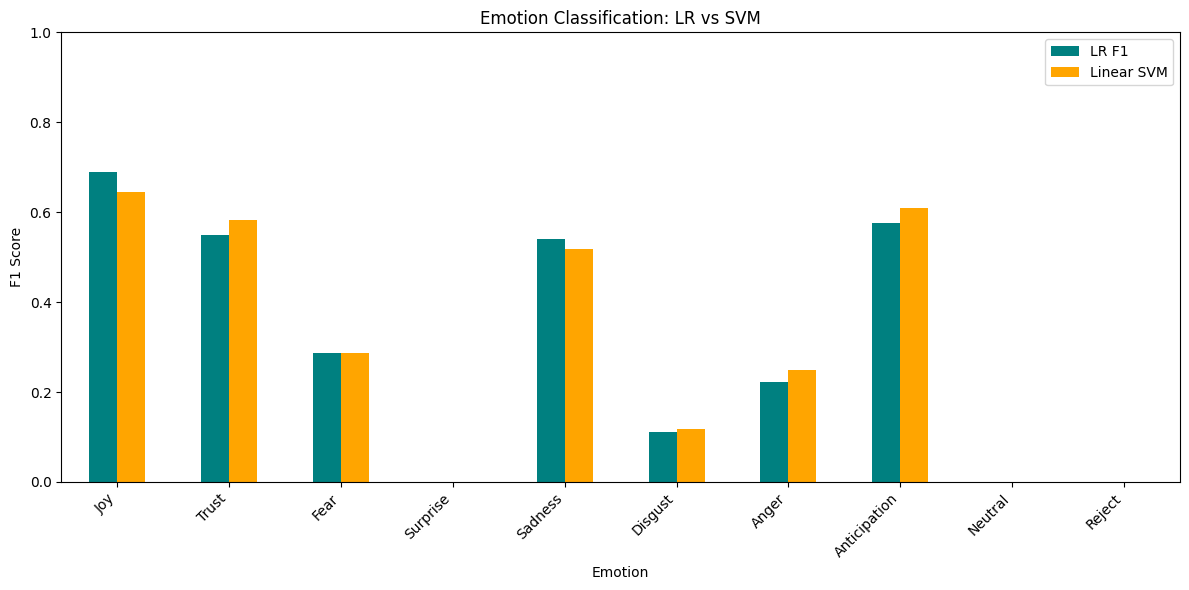

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

#Calculate F1 score for each emotion
lr_scores = f1_score(
    y_test, y_pred, average=None, zero_division=0
)

svm_scores = f1_score(
    y_test, y_pred_svm, average=None, zero_division=0
)

#Create a comparison table
comparison = pd.DataFrame({
    "Emotion": emotions,
    "LR F1": lr_scores,
    "Linear SVM": svm_scores
})

display(comparison.round(3))

# Plot comparison
ax = comparison.set_index("Emotion").plot(
    kind="bar",
    figsize=(12, 6),
    color=["teal", "orange"]
)

plt.title("Emotion Classification: LR vs SVM")
plt.xlabel("Emotion")
plt.ylabel("F1 Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


**Compare overall F1-scores**

In [16]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Micro F1": [
        f1_score(y_test, y_pred, average="micro"),
        f1_score(y_test, y_pred_svm, average="micro")
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, y_pred_svm, average="macro")
    ]
})

display(results.round(3))


,Model,Micro F1,Macro F1
0,Logistic Regression,0.508,0.297
1,Linear SVM,0.509,0.301


**What are Micro F1 and Macro F1?**

These are two different ways of summarizing performance across your 10 labels.

**MICRO F1**
0.508
> Counts all label-level predictions together before calculating F1.


**MACRO F1**
0.297
> Calculates F1 separately for each emotion, then averages the scores equally.

**What does the difference tell us?**

Your model performs considerably worse when every emotion receives equal importance. This reflects weak performance on several rare classes, even though it performs better on common emotions such as Joy.

**How does F1 help compare Logistic Regression and SVM?**

The purpose of F1 is to measure whether a model can reliably identify different emotions, especially the rare ones, and determine whether your proposed improvements actually work.

The original IEEE paper reports that its dataset contains:
- 1,112 sentences from mobile app reviews.
- 257 unique mobile applications.
- Reviews spanning 10 Google Play app categories.

We want to answer four questions:
1. How many different apps are in our notebook?
2. Which categories do these apps belong to?
3. How many apps belong to each category?
4. Which apps contribute the most review sentences?

In [17]:
#Check whether the dataset is loaded
print("Dataset shape:", df.shape)

#Display the first 5 rows
display(df.head())

Dataset shape: (1112, 21)


,iteration,app_name,categoryId,reviewId,sentenceId,at,score,feature,review,sentence,...,Trust,Fear,Surprise,Sadness,Disgust,Anger,Anticipation,Neutral,Reject,num_emotions
0,iteration_10,Telegram,COMMUNICATION,e19eb64e-fea0-4f11-a113-2d22cb7c4ddd,0,"Aug 30, 2022",5,f_339,"Telegram is not only the best messanger, but t...","Telegram is not only the best messanger, but t...",...,1,0,0,0,0,0,0,0,0,1
1,iteration_10,MixNote NotePad Notes,PRODUCTIVITY,51624ee8-b51e-456e-9d49-b0805fa7e60d,2,"Nov 12, 2017",5,f_30,Simple yet stylish and fast. I really love h...,"From Hiding private notes, cloud sync, and mak...",...,0,0,0,0,0,0,0,1,0,1
2,iteration_10,Productive - Habit tracker,PRODUCTIVITY,ce62d468-580a-48fe-97fc-08fd5e2bfc1a,2,"Aug 08, 2021",2,f_209,I m not satisfied at all. I got the one year p...,How can you charge so much without the ability...,...,0,0,1,1,0,0,0,0,0,2
3,iteration_10,Sygic GPS Navigation & Maps,MAPS_AND_NAVIGATION,c06118be-c6c0-42e9-9794-d3892b1b9f68,0,"Aug 31, 2022",5,f_26,Excel GPS navigation. Happy with it 😊,Excel GPS navigation.,...,0,0,0,0,0,0,0,0,0,1
4,iteration_10,TomTom Sports,HEALTH_AND_FITNESS,31430c83-3698-4aee-b7c4-fb0d57b9f90b,0,"Apr 14, 2020",3,f_278,Good app but I find some problem in synchroniz...,Good app but I find some problem in synchroniz...,...,0,0,0,1,0,0,0,0,0,2


Step 2 — Count the number of unique mobile apps

Now let's answer our first research question.

**- How many different mobile applications are represented in our dataset?**

In [19]:
#count the number of different mobile apps
total_unique_mobile_apps = df["app_name"].nunique()
print("Total number of unique mobile apps:", total_unique_mobile_apps)

Total number of unique mobile apps: 259


**Step 2 - Count the number of app categories**

In [23]:
#count the number of different app categories
total_categories = df["categoryId"].nunique()

print("Total number of app categories = ", total_categories)

#Display all category names
print("\n List of app categories:")
print(df["categoryId"].dropna().unique())

Total number of app categories =  10

 List of app categories:
['COMMUNICATION' 'PRODUCTIVITY' 'MAPS_AND_NAVIGATION' 'HEALTH_AND_FITNESS'
 'TRAVEL_AND_LOCAL' 'TOOLS' 'SOCIAL' 'WEATHER' 'LIFESTYLE'
 'PERSONALIZATION']


**Step 3 - How many apps belong to each category?**

In [24]:
# Group applications by categories
apps_per_category = (
    df.groupby("categoryId")["app_name"].nunique().sort_values(ascending=False)
)
print("Number of unique apps per category")

# Display the results
display(
apps_per_category.reset_index(name="Number of Apps")
)

Number of unique apps per category


,categoryId,Number of Apps
0,PRODUCTIVITY,94
1,HEALTH_AND_FITNESS,41
2,COMMUNICATION,30
3,TOOLS,28
4,WEATHER,21
5,TRAVEL_AND_LOCAL,13
6,MAPS_AND_NAVIGATION,12
7,SOCIAL,9
8,LIFESTYLE,7
9,PERSONALIZATION,4


In [25]:
#Make sure each app belongs to only one category
# Count categories associated with each app
categories_per_app = (
    df.groupby("app_name")["categoryId"]
    .nunique()
)

# Find apps assigned to multiple categories
multiple_categories = categories_per_app[
    categories_per_app > 1
]

print(
    "Apps belonging to multiple categories:",
    len(multiple_categories)
)

display(multiple_categories)


Apps belonging to multiple categories: 0


,categoryId
app_name,
